# Assignment 1: NLP Foundations, Regex & Text Processing (100 Points)

**Course Alignment:** Weeks 1 & 2 (Foundations, Regular Expressions, Tokenization & Text Preprocessing)  
**Submission:** Submit modular Python notebook (`.ipynb`) or script (`.py`) along with an exported HTML report.  
**Honor Code:** Work independently. Selective LLM assistance is permitted for debugging and iterative improvement.


In [1]:
import re, json, time, html, math, os
from collections import Counter, defaultdict

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 100)

## 1.1 - Paper Review (10):  

Select and review any one technical paper from the list of papers provide in Group1.

### Paper review

**Paper:** _Universal Sentence Encoder, Daniel Cer et al. (Google Research), EMNLP System Demonstrations, 2018_

**Problem:** The motivation of the paper was to give the ML community an encoder that generalizes better than word embeddings for NLP tasks which will benefit from better semantic representation of text.

**Method:**
- The authors propose an encoder that gives us a 512-dimensional embedding for a sentence. They provide two encoders:
    - Transformer based: uses attention to attend to each token in the sentence, and the per-token outputs are pooled into a single 512-dimensional vector.
    - DAN: averages over the unigram and bigram embeddings, then passes the average through a feedforward neural network.
- Both encoders are trained with multi-task learning on a skip-thought-style task, conversational input–response prediction, and SNLI classification. This is what makes them "universal."
- Since attention is n^2 complexity, they recommend using the DAN when the task has resource restrictions and can deal with some reduction in accuracy.

**Experiments and results:**
- The authors ran experiments with and without sentence encoding for transfer learning tasks like:
    - Movie review snippet sentiment
    - Sentiment of sentences mined from customer reviews
    - Phrase level opinion polarity, etc.
- These are tasks where you can clearly see that a sentence level understanding would be better than a word level one.
- They also proposed a method for these transfer learning tasks; they say the 'combined transfer models' generally yield better results. By combined, they mean combining the representations from a sentence level encoder with the representations from a word level encoder before the classification task layers.
- There is a further subdivision of experiments where the word embeddings are taken from w2v and where they are learned through the transfer learning task training set.
- The main finding is that sentence level transfer beats word level transfer, especially when training data is limited.
- The transformer based encoder is as good as or better than the DAN encoder, and does better when training samples are limited. The accuracy also depends on the size of the training data; as we train on more data, the performance across model setups starts converging.
- They also talk about their model showing weaker association patterns than GloVe for racism, ageism, and sexism.

**Strengths:**
- The importance of this model is practical: it gave the community ready-to-use pretrained sentence embeddings and showed how attention can generalize to multiple NLP classification tasks.
- It also makes the accuracy vs. compute tradeoff clear, showing the memory bottlenecks of attention compared to simpler methods like DAN.

**Weaknesses / limitations:**
- I am not impressed by the way they have covered the implementation. The paper was very vague about the implementation details, did not cover the experimentation methodology in detail, and did not elaborate on the encoder architectures. The experiment design was also presented very vaguely, and I had to infer most of it through the results table.
- The transfer tasks favor sentence level models by design, which limits how general the conclusion is.
- I think a good improvement might be ablations showing which training task contributes most, testing performance on longer texts, and reporting variance across runs.

**Takeaways:** The paper builds on foundations of the transformer architecture, transfer learning for NLP tasks, and replacing LSTMs for these tasks with a transformer based approach.

## 1.2 - News Article Scraping and Cleaning (20)

Scrape 50 recent news articles in English from multiple news websites and perform the following steps using basic python and regular expressions:

Write regex patterns to extract the following:
1. All the URLs present in the news articles and run it. Display the first 20 included URLs along with their associated article URLs.
2. The publication dates of the news articles and run it. Display the first 20 dates along with their associated article URLs.
3. Author names mentioned in the articles. Display the first 20 author names along with their associated article URLs.
4. Email addresses of the authors from the articles. Display the first 20 email addresses along with their associated article URLs.
5. All the phone numbers mentioned in the news articles. Display the first 20 phone numbers along with their associated article URLs
6. Clean the article text. Specially, you should remove HTML tags and special characters. Display the first 3 sentences of the pre-cleaned and post-cleaned text next to each other for the first 20 articles. 
7. All mentions of organizations or companies in the articles. Display the companies mentioned for the first 20 articles.
8. Clean the text and remove unnecessary whitespace and line breaks. Display the first 3 sentences of the pre-cleaned and post-cleaned text next to each other for the first 20 articles.
9. All the headlines or titles of the news articles. Display the first 20 headlines/titles along with their associated article URLs.
10. All the mentions of important events or incidents discussed in the articles. Display the first 20 important events along with their associated article URLs.

### Scraping 50 articles
RSS feeds give recent article links from five sources (10 each). Each article page is downloaded and the raw HTML is kept, so the regex tasks below run on real page markup. Results are cached in `news_articles.json`; delete it to scrape again.

In [2]:
HEADERS = {"User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 "
                         "(KHTML, like Gecko) Chrome/124.0 Safari/537.36"}
FEEDS = {
    "BBC":        "https://feeds.bbci.co.uk/news/world/rss.xml",
    "NPR":        "https://feeds.npr.org/1001/rss.xml",
    "Guardian":   "https://www.theguardian.com/world/rss",
    "Al Jazeera": "https://www.aljazeera.com/xml/rss/all.xml",
    "CBS News":   "https://www.cbsnews.com/latest/rss/main",
    "ABC News":   "https://abcnews.go.com/abcnews/topstories",   # backup source
}
N_ARTICLES, PER_SOURCE = 50, 10
CACHE = "news_articles.json"

ITEM_RE = re.compile(r"<item\b.*?</item>", re.S)
LINK_RE = re.compile(r"<link>\s*(?:<!\[CDATA\[)?(.*?)(?:\]\]>)?\s*</link>", re.S)
PARA_RE = re.compile(r"<p\b[^>]*>(.*?)</p>", re.S | re.I)
SKIP_URL_RE = re.compile(r"/(?:video|videos|live|live-updates|audio|av|gallery|podcasts?)/", re.I)
NOISE_RE = re.compile(r"<(script|style|noscript|figure|figcaption|aside|footer)\b.*?</\1>", re.S | re.I)
BOILERPLATE_RE = re.compile(r"hide caption|toggle caption|class=\"credit|external linking|browser is not fully supported|"
                            r"sign up for|newsletter|all rights reserved|cookies?\b", re.I)


def feed_links(feed_url):
    xml = requests.get(feed_url, headers=HEADERS, timeout=20).text
    links = [LINK_RE.search(item) for item in ITEM_RE.findall(xml)]
    links = [html.unescape(m.group(1).strip()) for m in links if m]
    return [u for u in links if not SKIP_URL_RE.search(u)]


def fetch_article(url, source):
    page = requests.get(url, headers=HEADERS, timeout=20)
    page.raise_for_status()
    page_html = page.content.decode("utf-8", errors="replace")   # all five sites serve UTF-8
    paras = [p.strip() for p in PARA_RE.findall(NOISE_RE.sub(" ", page_html))]
    # keep real body paragraphs (drop captions, footers, newsletter/cookie notices)
    paras = [p for p in paras if len(re.sub(r"<[^>]+>", "", p)) > 60 and not BOILERPLATE_RE.search(p)]
    body_html = "\n".join(f"<p>{p}</p>" for p in paras)
    return {"source": source, "url": page.url, "html": page_html, "body_html": body_html}


def scrape():
    articles = []
    for source, feed in FEEDS.items():
        if len(articles) >= N_ARTICLES:
            break
        kept = 0
        try:
            links = feed_links(feed)
        except Exception as e:
            print(f"{source}: feed failed ({e})")
            continue
        for url in links:
            if kept >= PER_SOURCE or len(articles) >= N_ARTICLES:
                break
            try:
                art = fetch_article(url, source)
            except Exception:
                continue
            if len(art["body_html"]) > 1500:          # skip pages with almost no text
                articles.append(art)
                kept += 1
            time.sleep(0.3)                             # be polite
        print(f"{source}: {kept} articles")
    return articles


if os.path.exists(CACHE):
    articles = json.load(open(CACHE))
else:
    articles = scrape()
    json.dump(articles, open(CACHE, "w"))

df = pd.DataFrame(articles)
print(len(df), "articles")
df.groupby("source").size()

BBC: 10 articles
NPR: 8 articles
Guardian: 10 articles
Al Jazeera: 10 articles
CBS News: 10 articles
ABC News: 2 articles
50 articles


source
ABC News       2
Al Jazeera    10
BBC           10
CBS News      10
Guardian      10
NPR            8
dtype: int64

In [3]:
# Helpers used by several tasks below
SCRIPT_STYLE_RE = re.compile(r"<(script|style|noscript)\b.*?</\1>", re.S | re.I)
TAG_RE = re.compile(r"<[^>]+>")
SENT_SPLIT_RE = re.compile(r"(?<=[.!?])\s+(?=[\"'“‘(]?[A-Z<])")


def strip_tags(text):
    """Remove scripts/styles and HTML tags and decode entities; keeps the original whitespace."""
    text = SCRIPT_STYLE_RE.sub(" ", text)
    text = TAG_RE.sub(" ", text)
    return html.unescape(text)


def first_sentences(text, n=3):
    return " ".join(SENT_SPLIT_RE.split(text.strip())[:n])


def show_first(rows, cols, n=20):
    out = pd.DataFrame(rows, columns=cols).head(n)
    out.index = range(1, len(out) + 1)
    return out


df["page_text"] = df["html"].map(strip_tags)       # all visible text on the page

#### 1. URLs

In [4]:
URL_RE = re.compile(r"""https?://[^\s"'<>()\[\]{}]+""")

rows = []
for _, a in df.iterrows():
    for u in dict.fromkeys(URL_RE.findall(a["body_html"])):     # links inside the article body (deduplicated)
        rows.append((html.unescape(u).rstrip(".,;"), a["url"]))
print("URLs found in article bodies:", len(rows))
print("URLs found in full pages:", sum(len(URL_RE.findall(h)) for h in df["html"]))
show_first(rows, ["included_url", "article_url"])

URLs found in article bodies: 174
URLs found in full pages: 13279


,included_url,article_url
1,http://bbcafrica.com/,https://www.bbc.co.uk/news/articles/ckd6d2l3dz4xo?at_medium=RSS&at_campaign=rss
2,https://twitter.com/BBCAfrica,https://www.bbc.co.uk/news/articles/ckd6d2l3dz4xo?at_medium=RSS&at_campaign=rss
3,https://www.facebook.com/BBCnewsafrica/,https://www.bbc.co.uk/news/articles/ckd6d2l3dz4xo?at_medium=RSS&at_campaign=rss
4,https://www.instagram.com/bbcafrica/,https://www.bbc.co.uk/news/articles/ckd6d2l3dz4xo?at_medium=RSS&at_campaign=rss
5,https://storage.courtlistener.com/recap/gov.uscourts.cand.480829/gov.uscourts.cand.480829.12.0_1.pdf,https://www.bbc.co.uk/news/articles/c6gel2dlyxvyo?at_medium=RSS&at_campaign=rss
6,http://bbcafrica.com/,https://www.bbc.co.uk/news/articles/c3lylj78777do?at_medium=RSS&at_campaign=rss
7,https://twitter.com/BBCAfrica,https://www.bbc.co.uk/news/articles/c3lylj78777do?at_medium=RSS&at_campaign=rss
8,https://www.facebook.com/BBCnewsafrica/,https://www.bbc.co.uk/news/articles/c3lylj78777do?at_medium=RSS&at_campaign=rss
9,https://www.instagram.com/bbcafrica/,https://www.bbc.co.uk/news/articles/c3lylj78777do?at_medium=RSS&at_campaign=rss
10,https://www.nellis.af.mil/Nellis-News/News-Releases/Display/Article/4628173/service-member-dies-following-incident-a...,https://www.bbc.co.uk/news/articles/crd6dn63j2xwo?at_medium=RSS&at_campaign=rss


#### 2. Publication dates

In [5]:
DATE_RE = re.compile(
    r'(?:"datePublished"\s*:\s*"|'                                   # JSON-LD
    r'(?:article:published_time|og:published_time|pubdate|publish-date|date)"\s+content="|'  # meta tags
    r'<time[^>]+datetime=")'                                          # <time datetime="...">
    r'(\d{4}-\d{2}-\d{2})', re.I)
URL_DATE_RE = re.compile(r"/(20\d{2})/(\d{2}|[a-z]{3})/(\d{2})/", re.I)
MONTHS = {m: f"{i:02d}" for i, m in enumerate(
    "jan feb mar apr may jun jul aug sep oct nov dec".split(), 1)}


def pub_date(a):
    m = DATE_RE.search(a["html"])
    if m:
        return m.group(1)
    m = URL_DATE_RE.search(a["url"])            # fallback: date in the URL path
    if m:
        y, mo, d = m.groups()
        return f"{y}-{MONTHS.get(mo.lower(), mo)}-{d}"
    return None


df["date"] = df.apply(pub_date, axis=1)
print("articles with a date:", df["date"].notna().sum(), "/", len(df))
show_first(df[["date", "url"]].values, ["date", "article_url"])

articles with a date: 50 / 50


,date,article_url
1,2026-10-19,https://www.bbc.co.uk/news/articles/cx30ez03djyqo?at_medium=RSS&at_campaign=rss
2,2026-10-19,https://www.bbc.co.uk/news/articles/cmj47yx572z5o?at_medium=RSS&at_campaign=rss
3,2026-10-19,https://www.bbc.co.uk/news/articles/ckd6d2l3dz4xo?at_medium=RSS&at_campaign=rss
4,2026-10-19,https://www.bbc.co.uk/news/articles/ckd7qy12j148o?at_medium=RSS&at_campaign=rss
5,2026-10-19,https://www.bbc.co.uk/weather/articles/c6dx07dznpyyo?at_medium=RSS&at_campaign=rss
6,2026-10-19,https://www.bbc.co.uk/news/articles/c6gel2dlyxvyo?at_medium=RSS&at_campaign=rss
7,2026-10-19,https://www.bbc.co.uk/news/articles/c3lylj78777do?at_medium=RSS&at_campaign=rss
8,2026-10-19,https://www.bbc.co.uk/news/articles/cv0ld6lrr2zeo?at_medium=RSS&at_campaign=rss
9,2026-10-19,https://www.bbc.co.uk/news/articles/crd6dn63j2xwo?at_medium=RSS&at_campaign=rss
10,2026-10-19,https://www.bbc.co.uk/news/articles/cr15jl7dd42vo?at_medium=RSS&at_campaign=rss


#### 3. Author names

In [6]:
NAME = r"[A-Z][a-zA-Z'’.-]+(?:\s+[A-Z][a-zA-Z'’.-]+){1,3}"
AUTHOR_RES = [
    re.compile(r'"author"\s*:\s*\[?\s*\{[^{}]*?"name"\s*:\s*"([^"]+)"'),          # JSON-LD
    re.compile(r'<meta[^>]+name="(?:author|byl|parsely-author)"[^>]+content="([^"]+)"', re.I),
    re.compile(r'rel="author"[^>]*>\s*(?:<[^>]+>\s*)*(' + NAME + r')'),           # byline link
    re.compile(r"\bBy\s+(" + NAME + r")"),                                         # "By Jane Doe"
]
NOT_AUTHOR_RE = re.compile(r"BBC|NPR|CBS|ABC|Guardian|Jazeera|News|Staff|Reuters|Associated Press", re.I)


def authors(a):
    found = []
    for rx in AUTHOR_RES:
        for name in rx.findall(a["html"] if rx.pattern.startswith(("\"", "<", "rel")) else a["page_text"]):
            name = re.sub(r"^By\s+", "", html.unescape(name)).strip()
            if name and not NOT_AUTHOR_RE.search(name) and name not in found:
                found.append(name)
        if found:
            break                                    # stop at the most reliable pattern that matched
    return found


df["authors"] = df.apply(authors, axis=1)
rows = [(n, a["url"]) for _, a in df.iterrows() for n in a["authors"]]
print("articles with an author:", (df["authors"].str.len() > 0).sum(), "/", len(df))
show_first(rows, ["author", "article_url"])

articles with an author: 35 / 50


,author,article_url
1,Jaroslav Lukiv,https://www.bbc.co.uk/news/articles/cx30ez03djyqo?at_medium=RSS&at_campaign=rss
2,Dan Johnson,https://www.bbc.co.uk/news/articles/cmj47yx572z5o?at_medium=RSS&at_campaign=rss
3,Thomas Mukhwana,https://www.bbc.co.uk/news/articles/ckd6d2l3dz4xo?at_medium=RSS&at_campaign=rss
4,Jack Burgess,https://www.bbc.co.uk/news/articles/ckd7qy12j148o?at_medium=RSS&at_campaign=rss
5,Sarah Keith-Lucas,https://www.bbc.co.uk/weather/articles/c6dx07dznpyyo?at_medium=RSS&at_campaign=rss
6,Laura Cress,https://www.bbc.co.uk/news/articles/c6gel2dlyxvyo?at_medium=RSS&at_campaign=rss
7,David Gritten,https://www.bbc.co.uk/news/articles/cv0ld6lrr2zeo?at_medium=RSS&at_campaign=rss
8,Brandon Drenon,https://www.bbc.co.uk/news/articles/crd6dn63j2xwo?at_medium=RSS&at_campaign=rss
9,Lisa Lambert,https://www.bbc.co.uk/news/articles/cr15jl7dd42vo?at_medium=RSS&at_campaign=rss
10,Rachel Treisman,https://www.npr.org/2026/10/19/nx-s1-6007746/golf-course-potomac-white-house-tree-removal


#### 4. Email addresses

In [7]:
EMAIL_RE = re.compile(r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b")
MAILTO_RE = re.compile(r'href="mailto:([^"?]+)', re.I)
# not real addresses: image names (logo@2x.png), error-tracking keys (hex@sentry.io), placeholders
NOT_EMAIL_RE = re.compile(r"\.(?:png|jpe?g|gif|svg|webp|js|css)$|@\dx\.|sentry|example\.com|^[0-9a-f]{16,}@", re.I)

rows = []
for _, a in df.iterrows():
    candidates = MAILTO_RE.findall(a["html"]) + EMAIL_RE.findall(a["page_text"])   # mailto links + visible text
    for e in dict.fromkeys(html.unescape(c).strip() for c in candidates):
        if not NOT_EMAIL_RE.search(e):
            rows.append((e, a["url"]))
print("emails found:", len(rows))
show_first(rows, ["email", "article_url"])

emails found: 0


,email,article_url


#### 5. Phone numbers

In [8]:
PHONE_RE = re.compile(r"""
    (?<![\w/.-])
    (?:
        (?:\+?1[\s.-]?)?\(?\d{3}\)?[\s.-]\d{3}[\s.-]\d{4}        # US: (312) 555-1234, 312-555-1234
      | \+\d{1,3}[\s.-]?\(?\d{1,4}\)?(?:[\s.-]?\d{2,4}){2,4}     # international: +44 20 7946 0958
      | 0\d{2,4}[\s-]\d{3,4}[\s-]?\d{3,4}                       # UK national: 020 7946 0958
      | \b\d{3}\b(?=\s+(?:hotline|crisis|helpline))             # short codes like 988
    )
    (?![\w/-])
""", re.X)

TEL_RE = re.compile(r'href="tel:([^"]+)"', re.I)

rows = []
for _, a in df.iterrows():
    text = re.sub(r"\s+", " ", a["page_text"])
    found = TEL_RE.findall(a["html"]) + PHONE_RE.findall(text)          # tel: links + numbers in the text
    for p in dict.fromkeys(m.strip() for m in found):
        rows.append((p, a["url"]))
print("phone numbers found:", len(rows), "(news articles rarely print phone numbers)")
show_first(rows, ["phone", "article_url"])

phone numbers found: 0 (news articles rarely print phone numbers)


,phone,article_url


#### 6. Remove HTML tags and special characters

In [9]:
SPECIAL_RE = re.compile(r"[^\w\s.,!?;:'\"%$()&-]")   # keep letters (incl. accented), digits and normal punctuation


def clean_html_special(text):
    text = strip_tags(text)                        # remove tags, decode &amp; &#39; ...
    text = text.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')
    text = text.replace("—", " - ").replace("–", "-")
    return SPECIAL_RE.sub(" ", text)              # whitespace is handled separately in task 8


df["text_no_html"] = df["body_html"].map(clean_html_special)
pd.DataFrame({
    "pre_cleaned": df["body_html"].map(first_sentences),
    "post_cleaned": df["text_no_html"].map(first_sentences),
}).head(20)

,pre_cleaned,post_cleaned
0,<p><b>French authorities have imposed overnight curfews in parts of central Paris and other cities after a weekend o...,French authorities have imposed overnight curfews in parts of central Paris and other cities after a weekend of riot...
1,"<p><b>Ukrainians have died because Kyiv is still not receiving reliable US warnings of incoming Russian attacks, acc...","Ukrainians have died because Kyiv is still not receiving reliable US warnings of incoming Russian attacks, according..."
2,"<p><b>The leader of a Kenyan doomsday cult, Paul Mackenzie, has been found guilty of murdering 191 people, all but o...","The leader of a Kenyan doomsday cult, Paul Mackenzie, has been found guilty of murdering 191 people, all but one of ..."
3,<p><b>Ukrainian tennis star Elina Svitolina has announced the end of her marriage with French former tennis player G...,Ukrainian tennis star Elina Svitolina has announced the end of her marriage with French former tennis player Gaël Mo...
4,<p><b>El Niño has been strengthening for several months now and is already having a significant impact on global wea...,El Niño has been strengthening for several months now and is already having a significant impact on global weather p...
5,<p><b>A Saudi national charged with secretly planting a recording device in one of OpenAI&#x27;s meeting rooms has b...,A Saudi national charged with secretly planting a recording device in one of OpenAI's meeting rooms has been accused...
6,"<p><b>A former Rwandan army sergeant major, who became an outspoken critic of President Paul Kagame, has been found ...","A former Rwandan army sergeant major, who became an outspoken critic of President Paul Kagame, has been found behead..."
7,<p><b>More than 50 security personnel have been killed and 200 injured in a Houthi missile strike on a camp in Yemen...,More than 50 security personnel have been killed and 200 injured in a Houthi missile strike on a camp in Yemen's cen...
8,<p><b>A member of the US Air Force died after he fell while abseiling from the ceiling of a Texas stadium ahead of a...,A member of the US Air Force died after he fell while abseiling from the ceiling of a Texas stadium ahead of a colle...
9,<p><b>Barack Obama has said congresswoman Ilhan Omar is under federal criminal investigation simply because she&#x27...,Barack Obama has said congresswoman Ilhan Omar is under federal criminal investigation simply because she's an outsp...


#### 7. Organizations and companies

In [10]:
CAP = r"(?:[A-Z][A-Za-z&'.-]+)"
ORG_SUFFIX = (r"(?:Inc|Corp|Corporation|Co|Ltd|LLC|plc|Group|Holdings|Company|Bank|Airlines?|Motors|"
              r"Technologies|Systems|Media|Ministry|Department|Agency|Council|Commission|Committee|"
              r"Parliament|Congress|Senate|Party|Union|Association|Organi[sz]ation|Federation|Foundation|"
              r"Institute|University|College|Court|Police|Army|Forces|Fund|Network|Times|Post|News)")
ORG_RE = re.compile(
    rf"\b(?:the\s+)?((?:{CAP}\s+){{0,4}}{ORG_SUFFIX}\b(?:\s+of(?:\s+the)?\s+{CAP}(?:\s+{CAP})*)?)"   # e.g. Bank of England
    rf"|\b((?:Ministry|Department|University|Bank)\s+of\s+(?:the\s+)?{CAP}(?:\s+{CAP})*)"
    rf"|\b([A-Z]{{2,6}})\b"                                                                       # acronyms: NATO, FBI
)
NOT_ORG = {"US", "UK", "EU", "AM", "PM", "TV", "CEO", "GMT", "BST", "ET", "PT", "AP", "OK", "II", "III",
           "USA", "DC", "LA", "NY", "ID", "PDF", "MP", "MPS", "HTML", "COVID", "AI"}
LEADING_JUNK = re.compile(r"^(?:The|A|An|In|At|On|For|But|And|Of|By|From|With|As|Its|His|Her|Their|This|That)\s+")


def organizations(text):
    found = []
    for g1, g2, g3 in ORG_RE.findall(text):
        org = LEADING_JUNK.sub("", (g1 or g2 or g3).strip())
        if org and org not in NOT_ORG and len(org) > 1 and org not in found:
            found.append(org)
    return found


df["text_clean"] = df["text_no_html"].map(lambda t: re.sub(r"\s+", " ", t).strip())
df["orgs"] = df["text_clean"].map(organizations)
pd.DataFrame({"article_url": df["url"], "organizations": df["orgs"].map(lambda o: ", ".join(o[:12]))}).head(20)

,article_url,organizations
0,https://www.bbc.co.uk/news/articles/cx30ez03djyqo?at_medium=RSS&at_campaign=rss,"Police, AFP, CCTV, CCI, RTL, BBC"
1,https://www.bbc.co.uk/news/articles/cmj47yx572z5o?at_medium=RSS&at_campaign=rss,"BBC, NBC, BBC News"
2,https://www.bbc.co.uk/news/articles/ckd6d2l3dz4xo?at_medium=RSS&at_campaign=rss,"BBC, Good News, Times, DNA"
3,https://www.bbc.co.uk/news/articles/ckd7qy12j148o?at_medium=RSS&at_campaign=rss,ATP
4,https://www.bbc.co.uk/weather/articles/c6dx07dznpyyo?at_medium=RSS&at_campaign=rss,"World Meteorological Agency, Indian Meteorological Department, IMD, Japanese Meteorological Agency"
5,https://www.bbc.co.uk/news/articles/c6gel2dlyxvyo?at_medium=RSS&at_campaign=rss,"BBC, FBI"
6,https://www.bbc.co.uk/news/articles/c3lylj78777do?at_medium=RSS&at_campaign=rss,"BBC, Rwanda National Congress, RNC"
7,https://www.bbc.co.uk/news/articles/cv0ld6lrr2zeo?at_medium=RSS&at_campaign=rss,"Yemen's Presidential Leadership Council, AFP"
8,https://www.bbc.co.uk/news/articles/crd6dn63j2xwo?at_medium=RSS&at_campaign=rss,"University of Texas, Tactical Air Control Party, UTSA"
9,https://www.bbc.co.uk/news/articles/cr15jl7dd42vo?at_medium=RSS&at_campaign=rss,"Department of Justice, BBC, Department, House Foreign Affairs Committee, CBS News, CBS"


#### 8. Remove unnecessary whitespace and line breaks

In [11]:
def normalize_whitespace(text):
    text = text.replace(" ", " ")                 # non-breaking spaces
    text = re.sub(r"[\r\n\t\f\v]+", " ", text)         # line breaks and tabs -> space
    text = re.sub(r" {2,}", " ", text)                 # runs of spaces -> one space
    text = re.sub(r"\s+([.,!?;:])", r"\1", text)       # no space before punctuation
    return text.strip()


df["text_clean"] = df["text_no_html"].map(normalize_whitespace)
pd.DataFrame({
    "pre_cleaned": df["text_no_html"].map(lambda t: repr(first_sentences(t))),   # repr shows \n and extra spaces
    "post_cleaned": df["text_clean"].map(first_sentences),
}).head(20)

,pre_cleaned,post_cleaned
0,'French authorities have imposed overnight curfews in parts of central Paris and other cities after a weekend of rio...,French authorities have imposed overnight curfews in parts of central Paris and other cities after a weekend of riot...
1,"'Ukrainians have died because Kyiv is still not receiving reliable US warnings of incoming Russian attacks, accordin...","Ukrainians have died because Kyiv is still not receiving reliable US warnings of incoming Russian attacks, according..."
2,"'The leader of a Kenyan doomsday cult, Paul Mackenzie, has been found guilty of murdering 191 people, all but one of...","The leader of a Kenyan doomsday cult, Paul Mackenzie, has been found guilty of murdering 191 people, all but one of ..."
3,'Ukrainian tennis star Elina Svitolina has announced the end of her marriage with French former tennis player Gaël M...,Ukrainian tennis star Elina Svitolina has announced the end of her marriage with French former tennis player Gaël Mo...
4,'El Niño has been strengthening for several months now and is already having a significant impact on global weather ...,El Niño has been strengthening for several months now and is already having a significant impact on global weather p...
5,'A Saudi national charged with secretly planting a recording device in one of OpenAI\'s meeting rooms has been accus...,A Saudi national charged with secretly planting a recording device in one of OpenAI's meeting rooms has been accused...
6,"'A former Rwandan army sergeant major, who became an outspoken critic of President Paul Kagame, has been found behea...","A former Rwandan army sergeant major, who became an outspoken critic of President Paul Kagame, has been found behead..."
7,'More than 50 security personnel have been killed and 200 injured in a Houthi missile strike on a camp in Yemen\'s c...,More than 50 security personnel have been killed and 200 injured in a Houthi missile strike on a camp in Yemen's cen...
8,"""A member of the US Air Force died after he fell while abseiling from the ceiling of a Texas stadium ahead of a coll...",A member of the US Air Force died after he fell while abseiling from the ceiling of a Texas stadium ahead of a colle...
9,'Barack Obama has said congresswoman Ilhan Omar is under federal criminal investigation simply because she\'s an out...,Barack Obama has said congresswoman Ilhan Omar is under federal criminal investigation simply because she's an outsp...


#### 9. Headlines / titles

In [12]:
TITLE_RES = [   # og:title meta tag (either attribute order, either quote style), then <h1>, then <title>
    re.compile(r"""<meta[^>]+property=["']og:title["'][^>]+content=(["'])(.*?)\1""", re.I),
    re.compile(r"""<meta[^>]+content=(["'])(.*?)\1[^>]+property=["']og:title["']""", re.I),
    re.compile(r"<h1\b[^>]*>(.*?)</h1>", re.S | re.I),
    re.compile(r"<title>(.*?)</title>", re.S | re.I),
]
SITE_SUFFIX_RE = re.compile(r"\s*[|\-–]\s*(?:BBC News|NPR|The Guardian|Al Jazeera|CBS News|ABC News).*$", re.I)


def headline(page):
    page = NOISE_RE.sub(" ", page)                      # ignore <h1> inside <noscript> warnings etc.
    for rx in TITLE_RES:
        m = rx.search(page)
        if m:
            title = normalize_whitespace(strip_tags(m.group(m.lastindex)))
            return SITE_SUFFIX_RE.sub("", title)
    return None


df["title"] = df["html"].map(headline)
show_first(df[["title", "url"]].values, ["headline", "article_url"])

,headline,article_url
1,Curfew imposed in parts of central Paris and other cities after rioting across France,https://www.bbc.co.uk/news/articles/cx30ez03djyqo?at_medium=RSS&at_campaign=rss
2,"Ukrainians dying because US restricting intelligence sharing, Zelensky adviser tells BBC",https://www.bbc.co.uk/news/articles/cmj47yx572z5o?at_medium=RSS&at_campaign=rss
3,Shakahola cult leader Paul Mackenzie guilty of 191 murder charges in Kenya,https://www.bbc.co.uk/news/articles/ckd6d2l3dz4xo?at_medium=RSS&at_campaign=rss
4,Tennis star Svitolina says emotional toll of Ukraine war led to Monfils separation,https://www.bbc.co.uk/news/articles/ckd7qy12j148o?at_medium=RSS&at_campaign=rss
5,Five ways El Niño is affecting the weather around the world,https://www.bbc.co.uk/weather/articles/c6dx07dznpyyo?at_medium=RSS&at_campaign=rss
6,"Ex-OpenAI worker accused of planting device had Saudi support, says court filing",https://www.bbc.co.uk/news/articles/c6gel2dlyxvyo?at_medium=RSS&at_campaign=rss
7,Robert Kabera: Critic of Rwandan President Paul Kagame found beheaded in Uganda,https://www.bbc.co.uk/news/articles/c3lylj78777do?at_medium=RSS&at_campaign=rss
8,"Houthi missile strike on Yemen camp kills 50 security recruits, authorities say",https://www.bbc.co.uk/news/articles/cv0ld6lrr2zeo?at_medium=RSS&at_campaign=rss
9,US airman dies as daredevil descent goes wrong before Texas college football game,https://www.bbc.co.uk/news/articles/crd6dn63j2xwo?at_medium=RSS&at_campaign=rss
10,Obama blasts Trump administration probe of congresswoman Ilhan Omar as 'so appalling',https://www.bbc.co.uk/news/articles/cr15jl7dd42vo?at_medium=RSS&at_campaign=rss


#### 10. Important events or incidents

In [13]:
EVENT_WORDS = (r"election|vote|referendum|summit|peace talks|ceasefire|truce|peace deal|agreement|deal|war|invasion|"
               r"attack|strike|airstrike|bombing|explosion|shooting|killing|killed|massacre|protest|riot|"
               r"crash|collision|earthquake|flood|wildfire|fire|hurricane|storm|typhoon|drought|outbreak|"
               r"pandemic|trial|verdict|sentenc\w+|indictment|arrest\w*|resign\w*|impeachment|coup|"
               r"shutdown|strike action|lawsuit|scandal|investigation|launch|tariffs?|sanctions|"
               r"inaugurat\w+|funeral|died|death|evacuation|hostage")
# a short noun phrase ending in an event word, e.g. "Israeli elections", "the drone strikes"
EVENT_RE = re.compile(rf"\b((?:[A-Z][\w'-]+\s+|[a-z][\w'-]+\s+){{0,3}}(?:{EVENT_WORDS})s?)\b", re.I)
STOP_LEAD_RE = re.compile(r"^(?:(?:the|a|an|of|in|on|at|to|and|after|before|was|were|is|are|has|have|had|"
                          r"that|which|who|it|its|their|his|her|said|says|for|by|with|from)\s+)+", re.I)


def events(text, k=3):
    """Return up to k (event phrase, sentence) pairs, scanning the opening sentences first."""
    found, seen = [], set()
    for sent in SENT_SPLIT_RE.split(text)[:15]:            # events in the lede matter most
        for m in EVENT_RE.finditer(sent):
            phrase = STOP_LEAD_RE.sub("", m.group(1)).strip()
            if phrase.lower() not in seen:
                seen.add(phrase.lower())
                found.append((phrase, sent[:160]))
    return found[:k]


df["events"] = df["text_clean"].map(events)
rows = [(e, s, a["url"]) for _, a in df.iterrows() for e, s in a["events"][:1]]   # main event per article
show_first(rows, ["event", "sentence", "article_url"])

,event,sentence,article_url
1,weekend of riots,French authorities have imposed overnight curfews in parts of central Paris and other cities after a weekend of riot...,https://www.bbc.co.uk/news/articles/cx30ez03djyqo?at_medium=RSS&at_campaign=rss
2,Ukrainians have died,"Ukrainians have died because Kyiv is still not receiving reliable US warnings of incoming Russian attacks, according...",https://www.bbc.co.uk/news/articles/cmj47yx572z5o?at_medium=RSS&at_campaign=rss
3,children to death,"Mackenzie ordered members of his cult to starve their children to death so they could ""meet Jesus"".",https://www.bbc.co.uk/news/articles/ckd6d2l3dz4xo?at_medium=RSS&at_campaign=rss
4,impact of the war,Ukrainian tennis star Elina Svitolina has announced the end of her marriage with French former tennis player Gaël Mo...,https://www.bbc.co.uk/news/articles/ckd7qy12j148o?at_medium=RSS&at_campaign=rss
5,been experiencing droughts,"Countries including Indonesia, India and the United States have been experiencing droughts, floods and heatwaves in ...",https://www.bbc.co.uk/weather/articles/c6dx07dznpyyo?at_medium=RSS&at_campaign=rss
6,son after his arrest,"US prosecutors claimed Abdulrahman Alfozan, who worked for the AI firm, was in ""frequent communication... with a mem...",https://www.bbc.co.uk/news/articles/c6gel2dlyxvyo?at_medium=RSS&at_campaign=rss
7,commented on the killing,The Rwandan government has not publicly commented on the killing.,https://www.bbc.co.uk/news/articles/c3lylj78777do?at_medium=RSS&at_campaign=rss
8,personnel have been killed,More than 50 security personnel have been killed and 200 injured in a Houthi missile strike on a camp in Yemen's cen...,https://www.bbc.co.uk/news/articles/cv0ld6lrr2zeo?at_medium=RSS&at_campaign=rss
9,US Air Force died,A member of the US Air Force died after he fell while abseiling from the ceiling of a Texas stadium ahead of a colle...,https://www.bbc.co.uk/news/articles/crd6dn63j2xwo?at_medium=RSS&at_campaign=rss
10,under federal criminal investigation,Barack Obama has said congresswoman Ilhan Omar is under federal criminal investigation simply because she's an outsp...,https://www.bbc.co.uk/news/articles/cr15jl7dd42vo?at_medium=RSS&at_campaign=rss


In [14]:
# Save the cleaned dataset for the later sections and the Streamlit app
df[["source", "url", "title", "date", "text_clean"]].to_csv("news_clean.csv", index=False)
docs = df["text_clean"].tolist()
titles = df["title"].tolist()

## 1.3 - News Text Processing (30)

#### Custom Tokenization and Stemming

1. Implement a basic tokenization function from scratch in Python. Your function should convert a text string into a list of words. Consider what delimiters (e.g., spaces, punctuation) you will use to separate the words.
2. Write a simple stemming function that processes a list of words and reduces each word to its root form. For simplicity, focus on the most common morphological endings in English (e.g., -ing, -ed, -s). Provide examples to demonstrate how your function works with these endings.
3. Apply your tokenization and stemming functions to the news dataset collected in Assignment 1. Display the first 5 articles' text before and after processing to illustrate the changes.

#### Preprocessing with Custom Functions

4. After applying your custom tokenization and stemming functions to the news dataset, remove stopwords. Since you are implementing functions from scratch, create a basic list of stopwords manually and use it for filtering.
5. Visualize the frequency distribution of the top 20 most common words in the preprocessed news dataset. Compare this visualization with the one obtained in Assignment 1 to discuss the impact of stemming and stopword removal on word frequencies.

#### NLTK and SpaCy

6. Use NLTK and SpaCy to tokenize and stem/lemmatize the same news dataset. 
7. Compare the output of your custom functions with that of NLTK and SpaCy. Discuss any differences in the results, considering aspects such as the number of tokens produced, stemming accuracy, and processing time.
8. Using only Edit distance method to compare the news articles with each other. Find the top two most similar articles.

#### Additional Challenges (Optional)

9. (Optional) Extend your stemming function to handle more complex cases of morphology, such as irregular verbs or nouns (e.g., "went" to "go", "mice" to "mouse").
10. (Optional) Implement a basic Part-of-Speech (POS) tagging function using regular expressions or simple heuristics and apply it to your news dataset. Compare your results with POS tagging done by SpaCy.

#### 1. Tokenization from scratch

In [35]:
def tokenize(text, lowercase=True):
    """Split text into words. A word is a run of letters/digits; an apostrophe or hyphen
    is kept only between two letters (don't, well-known). Everything else is a delimiter."""
    tokens, current = [], []
    n = len(text)
    for i, ch in enumerate(text):
        if ch.isalnum():
            current.append(ch)
        elif ch in "'’-" and current and i + 1 < n and text[i + 1].isalpha() and current[-1].isalpha():
            current.append("'" if ch == "’" else ch)
        else:                                   # space, punctuation, symbol -> end of word
            if current:
                tokens.append("".join(current))
                current = []
    if current:
        tokens.append("".join(current))
    return [t.lower() for t in tokens] if lowercase else tokens


print(tokenize("Mr. O'Neil's well-known start-up raised $4.5m in 2024"))

['mr', "o'neil's", 'well-known', 'start-up', 'raised', '4', '5m', 'in', '2024']


#### 2. Stemming from scratch

In [52]:
VOWELS = set("aeiou")


def _has_vowel(s):
    return any(c in VOWELS for c in s) or (len(s) > 1 and "y" in s[1:])


def _tidy(stem):
    """Clean up a stem after removing -ing/-ed: undouble (running->run), restore e (hoping->hope)."""
    if len(stem) > 2 and stem[-1] == stem[-2] and stem[-1] not in "lsz":
        return stem[:-1]
    if stem.endswith(("at", "bl", "iz")):
        return stem + "e"
    # short consonant-vowel-consonant stem with one vowel group: vot -> vote, liv -> live
    if (len(re.findall(r"[aeiou]+", stem)) == 1 and re.search(r"[^aeiou][aeiou][^aeiouwxy]$", stem)):
        return stem + "e"
    return stem


def stem(word):
    w = word.lower()
    if len(w) <= 3 or not w.isalpha():
        return w
    # plurals / 3rd person -s
    if w.endswith("sses"):
        w = w[:-2]                                    # classes -> class
    elif w.endswith("ies") and len(w) > 4:
        w = w[:-3] + "y"                              # policies -> policy
    elif w.endswith("s") and not w.endswith(("ss", "us", "is")):
        w = w[:-1]                                    # reports -> report
    # past tense / progressive
    if w.endswith("eed"):
        return w if len(w) <= 4 else w[:-1]          # agreed -> agree
    for suffix in ("ing", "ed"):
        if w.endswith(suffix) and _has_vowel(w[:-len(suffix)]) and len(w) - len(suffix) >= 3:
            w = _tidy(w[:-len(suffix)])
            break
    # a few other common endings
    for suffix, repl in ( ("ization", "ize"), ("fulness", "ful"),
                         ("ousness", "ous"), ("ness", ""), ("ly", ""), ("ational", "ate")):
        if w.endswith(suffix) and len(w) - len(suffix) >= 4:
            return w[: -len(suffix)] + repl
    return w


examples = ["runnization", "jumped", "hoping", "stopped", "reports", "classes", "policies", "agreed",
            "talking", "voted", "elections", "bus", "analysis", "sing", "quickly", "kindness", "callousness", "rational"]
pd.DataFrame({"word": examples, "stem": [stem(w) for w in examples]}).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
word,runnization,jumped,hoping,stopped,reports,classes,policies,agreed,talking,voted,elections,bus,analysis,sing,quickly,kindness,callousness,rational
stem,runnize,jump,hope,stop,report,class,policy,agree,talk,vote,election,bus,analysis,sing,quick,kind,callous,rational


#### 3. Apply to the news dataset

In [53]:
df["tokens"] = df["text_clean"].map(tokenize)
df["stems"] = df["tokens"].map(lambda toks: [stem(t) for t in toks])

for i in range(5):
    print(f"--- Article {i + 1}: {df.loc[i, 'title']}")
    print("BEFORE:", df.loc[i, "text_clean"][:300], "...")
    print("TOKENS:", df.loc[i, "tokens"][:40])
    print("STEMS :", df.loc[i, "stems"][:40], "\n")

--- Article 1: Curfew imposed in parts of central Paris and other cities after rioting across France
BEFORE: French authorities have imposed overnight curfews in parts of central Paris and other cities after a weekend of riots and looting across the country. Police in Paris said a curfew would be in force between 23:00 local time (21:00 GMT) and 06:00 in Place de la République, where protesters had gathere ...
TOKENS: ['french', 'authorities', 'have', 'imposed', 'overnight', 'curfews', 'in', 'parts', 'of', 'central', 'paris', 'and', 'other', 'cities', 'after', 'a', 'weekend', 'of', 'riots', 'and', 'looting', 'across', 'the', 'country', 'police', 'in', 'paris', 'said', 'a', 'curfew', 'would', 'be', 'in', 'force', 'between', '23', '00', 'local', 'time', '21']
STEMS : ['french', 'authority', 'have', 'impos', 'overnight', 'curfew', 'in', 'part', 'of', 'central', 'paris', 'and', 'other', 'city', 'after', 'a', 'weekend', 'of', 'riot', 'and', 'loot', 'across', 'the', 'country', 'police', 'in'

#### 4. Stopword removal

In [18]:
STOPWORDS = set("""
a about above after again against all also am an and any are aren't as at be because been before being
below between both but by can can't could couldn't did didn't do does doesn't doing don't down during each
few for from further had hadn't has hasn't have haven't having he he'd he'll he's her here here's hers
herself him himself his how how's i i'd i'll i'm i've if in into is isn't it it's its itself just let's me
more most mustn't my myself no nor not now of off on once only or other ought our ours ourselves out over
own same shan't she she'd she'll she's should shouldn't so some such than that that's the their theirs them
themselves then there there's these they they'd they'll they're they've this those through to too under
until up very was wasn't we we'd we'll we're we've were weren't what what's when when's where where's which
while who who's whom why why's will with won't would wouldn't you you'd you'll you're you've your yours
yourself yourselves said says say one two new also would could may might us mr mrs ms
""".split())
STOP_STEMS = {stem(w) for w in STOPWORDS} | STOPWORDS     # stopwords may have been stemmed too


def remove_stopwords(tokens):
    return [t for t in tokens if t not in STOP_STEMS and t.isalpha() and len(t) > 1]


df["processed"] = df["stems"].map(remove_stopwords)
print("tokens before:", df["tokens"].str.len().sum(), " after stemming + stopword removal:", df["processed"].str.len().sum())
print(df.loc[0, "processed"][:40])

tokens before: 37864  after stemming + stopword removal: 19497
['french', 'authority', 'impos', 'overnight', 'curfew', 'part', 'central', 'paris', 'city', 'weekend', 'riot', 'loot', 'across', 'country', 'police', 'paris', 'curfew', 'force', 'local', 'time', 'gmt', 'place', 'de', 'la', 'république', 'protester', 'gather', 'weekend', 'les', 'halle', 'shop', 'area', 'ban', 'unauthoris', 'gather', 'impos', 'several', 'part', 'city', 'centre']


#### 5. Frequency distribution of the top 20 words

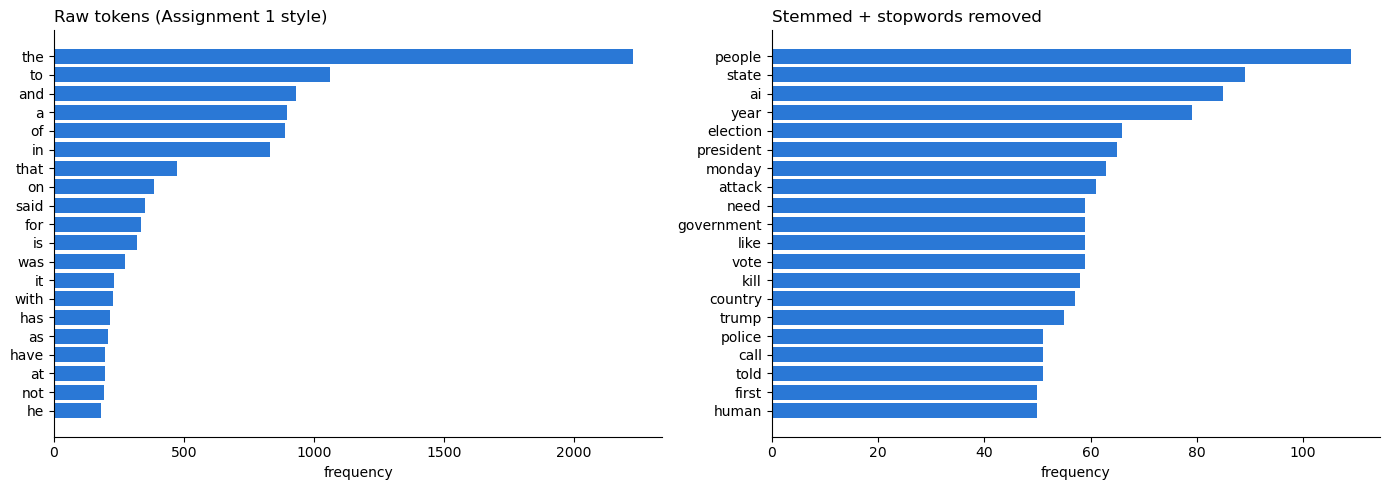

vocabulary size raw: 6654  processed: 4629


In [19]:
raw_counts = Counter(t for toks in df["tokens"] for t in toks)        # plain tokens (no stemming / stopwords)
proc_counts = Counter(t for toks in df["processed"] for t in toks)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, counts, name in [(axes[0], raw_counts, "Raw tokens (Assignment 1 style)"),
                         (axes[1], proc_counts, "Stemmed + stopwords removed")]:
    words, freqs = zip(*counts.most_common(20))
    ax.barh(words[::-1], freqs[::-1], color="#2a78d6")
    ax.set_title(name, loc="left")
    ax.set_xlabel("frequency")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print("vocabulary size raw:", len(raw_counts), " processed:", len(proc_counts))

**Effect of stemming and stopword removal**

The raw top 20 is almost all function words. "the" appears about 2,200 times, and "to", "and", "a", "of" and "in" each appear 800 to 1,000 times. The only word in that list that says anything about news is "said".

After stemming and stopword removal the top 20 shows the topics of the dataset: people, state, AI, election, president, attack, government, vote, kill, police and Trump. The counts are much smaller and much flatter, because the very frequent function words are gone.

Stemming also merges word forms. "kill" combines killed, killing and kills, and "vote" combines votes, voted and voting, so these words rank higher than any single form would. The vocabulary drops from 6,654 to 4,629 distinct words which is about 30% smaller.

Some low-information words remain: "monday", "like", "need", "told", "first" and "call". They are reporting and time words that are not in my stopword list. Adding them, or weighting by TF-IDF, would make the list more topical.

#### 6. NLTK and spaCy

In [20]:
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer
import spacy

for pkg in ["punkt", "punkt_tab", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

porter, wnl = PorterStemmer(), WordNetLemmatizer()
nlp = spacy.load("en_core_web_sm")

timings = {}

t0 = time.perf_counter()
custom = [[stem(t) for t in tokenize(d)] for d in docs]
timings["custom"] = time.perf_counter() - t0

t0 = time.perf_counter()
nltk_tokens = [word_tokenize(d) for d in docs]
nltk_stems = [[porter.stem(t) for t in toks] for toks in nltk_tokens]
nltk_lemmas = [[wnl.lemmatize(t.lower()) for t in toks] for toks in nltk_tokens]
timings["nltk"] = time.perf_counter() - t0

t0 = time.perf_counter()
spacy_docs = list(nlp.pipe(docs, batch_size=16))
spacy_tokens = [[t.text for t in d] for d in spacy_docs]
spacy_lemmas = [[t.lemma_.lower() for t in d] for d in spacy_docs]
timings["spacy"] = time.perf_counter() - t0

print("NLTK tokens  :", nltk_tokens[0][:25])
print("NLTK Porter  :", nltk_stems[0][:25])
print("spaCy tokens :", spacy_tokens[0][:25])
print("spaCy lemmas :", spacy_lemmas[0][:25])

NLTK tokens  : ['French', 'authorities', 'have', 'imposed', 'overnight', 'curfews', 'in', 'parts', 'of', 'central', 'Paris', 'and', 'other', 'cities', 'after', 'a', 'weekend', 'of', 'riots', 'and', 'looting', 'across', 'the', 'country', '.']
NLTK Porter  : ['french', 'author', 'have', 'impos', 'overnight', 'curfew', 'in', 'part', 'of', 'central', 'pari', 'and', 'other', 'citi', 'after', 'a', 'weekend', 'of', 'riot', 'and', 'loot', 'across', 'the', 'countri', '.']
spaCy tokens : ['French', 'authorities', 'have', 'imposed', 'overnight', 'curfews', 'in', 'parts', 'of', 'central', 'Paris', 'and', 'other', 'cities', 'after', 'a', 'weekend', 'of', 'riots', 'and', 'looting', 'across', 'the', 'country', '.']
spaCy lemmas : ['french', 'authority', 'have', 'impose', 'overnight', 'curfew', 'in', 'part', 'of', 'central', 'paris', 'and', 'other', 'city', 'after', 'a', 'weekend', 'of', 'riot', 'and', 'loot', 'across', 'the', 'country', '.']


#### 7. Compare custom vs NLTK vs spaCy

In [21]:
summary = pd.DataFrame({
    "tool": ["custom", "NLTK (word_tokenize + Porter)", "spaCy (en_core_web_sm)"],
    "total_tokens": [sum(map(len, custom)), sum(map(len, nltk_tokens)), sum(map(len, spacy_tokens))],
    "unique_stems_or_lemmas": [len({s for d in custom for s in d}),
                               len({s for d in nltk_stems for s in d}),
                               len({s for d in spacy_lemmas for s in d})],
    "seconds": [timings["custom"], timings["nltk"], timings["spacy"]],
}).round(3)
display(summary)

# Same words through all three: where do they agree / disagree?
sample = ["running", "studies", "elections", "went", "children", "better", "voted", "officials",
          "said", "leaders", "hoping", "mice", "agreed", "was", "fighting", "countries"]
pd.DataFrame({
    "word": sample,
    "custom": [stem(w) for w in sample],
    "porter": [porter.stem(w) for w in sample],
    "wordnet_lemma": [wnl.lemmatize(w, pos="v") if w.endswith(("ing", "ed")) or w in ("went", "was") else wnl.lemmatize(w) for w in sample],
    "spacy_lemma": [nlp(w)[0].lemma_ for w in sample],
})

,tool,total_tokens,unique_stems_or_lemmas,seconds
0,custom,37864,5405,0.026
1,NLTK (word_tokenize + Porter),43729,4944,1.375
2,spaCy (en_core_web_sm),44541,5213,4.874


,word,custom,porter,wordnet_lemma,spacy_lemma
0,running,run,run,run,run
1,studies,study,studi,study,study
2,elections,election,elect,election,election
3,went,went,went,go,go
4,children,children,children,child,child
5,better,better,better,better,well
6,voted,vote,vote,vote,vote
7,officials,official,offici,official,official
8,said,said,said,said,say
9,leaders,leader,leader,leader,leader


**Custom vs NLTK vs spaCy**

*Number of tokens.* Our custom tokenizer produced 37,864 tokens, NLTK 43,729 and spaCy 44,541. The difference is mostly punctuation and contractions. NLTK and spaCy keep punctuation marks as tokens and split "didn't" into "did" + "n't" and "Russia's" into "Russia" + "'s". My tokenizer drops punctuation and keeps contractions as one word.

*Stemming / lemmatization accuracy.*
- Porter is the most aggressive. It merges the most forms, but many stems are not real words: "studi", "countri", "offici", "agre", "wa".
- My stemmer gives real words for regular endings ("study", "country", "official", "agree", "vote"). It is less aggressive, so it has more unique stems
- Neither stemmer handles irregular forms. "went", "children", "mice", "was" and "said" stay unchanged. Only the lemmatizers map them to "go", "child", "mouse", "be" and "say".
- spaCy uses the part-of-speech tag, so "said" becomes "say". The tag is guessed from context, so isolated words can go wrong: "better" became "well" because it was tagged as an adverb. "hoping" became "hop" for both WordNet and spaCy, while both stemmers gave "hope".

 Mine took 0.026 s, NLTK 1.4 s (about 50× slower) and spaCy 4.9 s (about 190× slower). spaCy is slowest because it runs a full pipeline (tagger, parser, entity recognizer) on every article. Mine is fastest because it is a single pass with very few suffix rules.

We can say that the custom functions are fast and good enough for search over clean text. Lemmatization gives the most linguistically correct base forms, at the cost of speed.

#### 8. Most similar articles by edit distance

In [ ]:
def edit_distance(a, b):
    """Levenshtein distance between two sequences (insert / delete / substitute cost 1)."""
    if len(a) < len(b):
        a, b = b, a
    prev = list(range(len(b) + 1))
    for i, x in enumerate(a, 1):
        cur = [i]
        for j, y in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (x != y)))
        prev = cur
    return prev[-1]


print(edit_distance("kitten", "sitting"))    # 3

# Word-level edit distance on the first 150 preprocessed tokens of each article
N_TOK = 150
seqs = [toks[:N_TOK] for toks in df["processed"]]
n = len(seqs)
sim = np.zeros((n, n))
t0 = time.perf_counter()
for i in range(n):
    for j in range(i + 1, n):
        d = edit_distance(seqs[i], seqs[j])
        sim[i, j] = sim[j, i] = 1 - d / max(len(seqs[i]), len(seqs[j]))   # normalized similarity
print(f"{n * (n - 1) // 2} pairs in {time.perf_counter() - t0:.1f}s")

pairs = sorted(((sim[i, j], i, j) for i in range(n) for j in range(i + 1, n)), reverse=True)
s, i, j = pairs[0]
print(f"\nMost similar pair (similarity {s:.3f}):\n  [{i}] {titles[i]}\n  [{j}] {titles[j]}")
pd.DataFrame([(round(s, 3), titles[i], titles[j]) for s, i, j in pairs[:5]],
             columns=["similarity", "article_a", "article_b"])

3
1225 pairs in 2.7s

Most similar pair (similarity 0.060):
  [41] Boy among 2 killed after truck drives onto Wichita soccer field, 11 others injured, police say
  [45] 1 person killed in shooting near Columbus, Ohio, mosque, police say


,similarity,article_a,article_b
0,0.060,"Boy among 2 killed after truck drives onto Wichita soccer field, 11 others injured, police say","1 person killed in shooting near Columbus, Ohio, mosque, police say"
1,0.053,France's leaders vow to restore order after weekend of violent riots across the country,"1 person killed in shooting near Columbus, Ohio, mosque, police say"
2,0.053,"Gun used in Oregon elementary school shooting was birthday gift from shooter's mom, sources say","1 person killed in shooting near Columbus, Ohio, mosque, police say"
3,0.047,"Transcript: Rep. Mike Turner on ""Face the Nation with Margaret Brennan,"" Oct. 18, 2026","1 person killed in shooting near Columbus, Ohio, mosque, police say"
4,0.047,Feds investigating suspicious letters sent to election officials and congressional offices,"1 person killed in shooting near Columbus, Ohio, mosque, police say"


**Interpretation**

The most similar pair is "Boy among 2 killed after truck drives onto Wichita soccer field" and "1 person killed in shooting near Columbus, Ohio, mosque". Both are short CBS crime reports with the same structure: someone killed, police say, an investigation. Their similarity is still only 0.06. Edit distance compares words in order, so two articles score high only if they use the same words in the same sequence. Different news articles almost never do.

The method also misses articles about the same story. The dataset has the Kenyan cult-leader verdict from both the BBC and the Guardian (both appear in the BM25 results below), and they are not the top pair because they word the story differently. Edit distance measures surface similarity, not topic similarity. Bag-of-words cosine (TF-IDF) or embeddings are better suited to comparing documents.

#### 9. Irregular forms

In [23]:
IRREGULAR = {
    # verbs
    "went": "go", "gone": "go", "goes": "go", "was": "be", "were": "be", "been": "be", "is": "be", "are": "be",
    "had": "have", "has": "have", "did": "do", "does": "do", "done": "do", "said": "say", "says": "say",
    "made": "make", "took": "take", "taken": "take", "came": "come", "saw": "see", "seen": "see",
    "got": "get", "gotten": "get", "gave": "give", "given": "give", "told": "tell", "found": "find",
    "thought": "think", "left": "leave", "felt": "feel", "kept": "keep", "began": "begin", "begun": "begin",
    "ran": "run", "brought": "bring", "bought": "buy", "held": "hold", "led": "lead", "met": "meet",
    "paid": "pay", "sent": "send", "spent": "spend", "built": "build", "fought": "fight", "won": "win",
    "lost": "lose", "fell": "fall", "fallen": "fall", "rose": "rise", "risen": "rise", "struck": "strike",
    "wrote": "write", "written": "write", "spoke": "speak", "spoken": "speak", "chose": "choose",
    "knew": "know", "known": "know", "grew": "grow", "grown": "grow", "drew": "draw", "flew": "fly",
    "sought": "seek", "caught": "catch", "taught": "teach", "stood": "stand", "understood": "understand",
    # nouns
    "mice": "mouse", "men": "man", "women": "woman", "children": "child", "people": "person",
    "feet": "foot", "teeth": "tooth", "geese": "goose", "lives": "life", "wives": "wife",
    "knives": "knife", "leaves": "leaf", "halves": "half", "crises": "crisis", "analyses": "analysis",
    "criteria": "criterion", "phenomena": "phenomenon", "data": "datum", "media": "medium",
    # adjectives
    "better": "good", "best": "good", "worse": "bad", "worst": "bad",
}


def stem_v2(word):
    w = word.lower()
    if w in IRREGULAR:
        return IRREGULAR[w]
    if w.endswith("ves") and len(w) > 4:            # wolves -> wolf
        return w[:-3] + "f"
    return stem(w)


tests = ["went", "mice", "children", "running", "wolves", "fought", "crises", "better", "voted"]
pd.DataFrame({"word": tests, "stem_v1": [stem(w) for w in tests], "stem_v2": [stem_v2(w) for w in tests]}).T

,0,1,2,3,4,5,6,7,8
word,went,mice,children,running,wolves,fought,crises,better,voted
stem_v1,went,mice,children,run,wolve,fought,crise,better,vote
stem_v2,go,mouse,child,run,wolf,fight,crisis,good,vote


#### 10. Rule-based POS tagger vs spaCy

In [24]:
CLOSED = {
    "DET": "the a an this that these those every each some any no another".split(),
    "PRON": "i you he she it we they me him her us them my your his its our their who whom".split(),
    "ADP": "in on at by for with from to of into over under about after before between during against through".split(),
    "CCONJ": "and or but nor yet so".split(),
    "AUX": "is are was were be been being am has have had do does did will would can could should may might must".split(),
    "PART": "not n't 's".split(),
}
WORD2TAG = {w: tag for tag, ws in CLOSED.items() for w in ws}
SUFFIX_RULES = [
    (r"^\d+([.,]\d+)?$", "NUM"),
    (r"^[^\w\s]+$", "PUNCT"),
    (r".*ly$", "ADV"),
    (r".*(ing|ed|ize|ise|ate|ify)$", "VERB"),
    (r".*(ous|ful|ive|able|ible|al|ic|less|ish|est|er)$", "ADJ"),
    (r".*(tion|sion|ment|ness|ity|ship|ism|ist|er|or|s)$", "NOUN"),
]


def pos_tag(tokens):
    tags = []
    for i, tok in enumerate(tokens):
        low = tok.lower()
        if low in WORD2TAG:
            tag = WORD2TAG[low]
        elif tok[:1].isupper() and i > 0:
            tag = "PROPN"                              # capitalized mid-sentence -> proper noun
        else:
            tag = next((t for rx, t in SUFFIX_RULES if re.match(rx, low)), "NOUN")
        tags.append(tag)
    return tags


# compare on spaCy's own tokenization so the tags line up one-to-one
d = spacy_docs[0]
toks = [t.text for t in d]
ours = pos_tag(toks)
gold = [t.pos_ for t in d]
agree = np.mean([a == b for a, b in zip(ours, gold)])
print(f"Agreement with spaCy on article 1: {agree:.1%}")

all_ours, all_gold = [], []
for d in spacy_docs:
    all_ours += pos_tag([t.text for t in d])
    all_gold += [t.pos_ for t in d]
print(f"Agreement on all articles: {np.mean([a == b for a, b in zip(all_ours, all_gold)]):.1%}")
pd.DataFrame({"token": toks[:30], "rule_based": ours[:30], "spacy": gold[:30]}).T

Agreement with spaCy on article 1: 81.1%
Agreement on all articles: 77.1%


,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,25,26,27,28,29
token,French,authorities,have,imposed,overnight,curfews,in,parts,of,central,...,looting,across,the,country,.,Police,in,Paris,said,a
rule_based,NOUN,NOUN,AUX,VERB,NOUN,NOUN,ADP,NOUN,ADP,ADJ,...,VERB,NOUN,DET,NOUN,PUNCT,PROPN,ADP,PROPN,NOUN,DET
spacy,ADJ,NOUN,AUX,VERB,ADJ,NOUN,ADP,NOUN,ADP,ADJ,...,VERB,ADP,DET,NOUN,PUNCT,NOUN,ADP,PROPN,VERB,DET


**Comparison with spaCy**

The rule-based tagger agrees with spaCy on 81.1% of tokens in the first article and 77.1% overall. It handles closed-class words (determiners, prepositions, conjunctions, auxiliaries), punctuation, and regular verbs ending in -ing/-ed.

Its errors come from things a lookup and suffix rules cannot see:
- Words whose tag depends on context: "French" and "overnight" are adjectives here, but the rules default to NOUN.
- Words missing from the closed lists: "across" was tagged NOUN instead of ADP.
- Irregular verbs: "said" has no -ed ending, so it was tagged NOUN instead of VERB.
- Capitalization: "Police" at the start of a sentence was tagged PROPN, while spaCy correctly says NOUN.

spaCy uses a statistical model trained on annotated text, so it uses surrounding words to choose the tag. That accounts for most of the remaining 23%.

## 1.4 - Keyword Search (20)


### TF-IDF with Scikit-Learn

1. Use the scikit-learn library to compute TF-IDF scores for the news dataset.
2. Write the Python code to transform the news dataset into a TF-IDF matrix using TfidfVectorizer from scikit-learn. Highlight how to adjust parameters like max_features, ngram_range, and stop_words.
3. Select three articles from your dataset and display the top 5 terms with the highest TF-IDF scores for each. Discuss how these terms help in understanding the main topics of the articles.

###  Implementing Okapi BM25

4. Explain the Okapi BM25 algorithm and its advantages over TF-IDF for ranking documents based on query relevance.
5. Implement a basic version of the Okapi BM25 algorithm in Python. Provide a clear explanation of your implementation steps, including the computation of IDF and BM25 scores.
6. Use your Okapi BM25 implementation to rank all news articles in your dataset based on their relevance to a user-defined query (e.g., "climate change"). Display the top 5 ranked articles and discuss the relevance of the results.

### Exploring Word Embeddings

7. Use a pre-trained Word2Vec or GloVe model (available through libraries like Gensim or SpaCy) to transform words from the news articles into vectors.
8. Select any 10 words from your dataset (e.g., names of organizations, places, and common nouns) and use the pre-trained embeddings to find the 3 most similar words for each. Discuss the semantic similarities and differences among the words and their most similar counterparts.
9. Visualize word embeddings for a subset of words from your dataset using a dimensionality reduction technique (e.g., PCA or t-SNE).
10. Provide a brief explanation of the visualization technique used and interpret the resulting plot.

#### 1-2. TF-IDF matrix with `TfidfVectorizer`

In [25]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Default settings: unigrams, no stopword removal, every term kept
tfidf_default = TfidfVectorizer()
X_default = tfidf_default.fit_transform(docs)
print("default            :", X_default.shape)

# Tuned settings
tfidf = TfidfVectorizer(
    stop_words="english",      # drop common English function words
    ngram_range=(1, 2),        # unigrams and bigrams ("climate change", "white house")
    max_features=5000,         # keep the 5000 terms with the highest corpus frequency
    min_df=2,                  # ignore terms that appear in only one article
    max_df=0.8,                # ignore terms that appear in >80% of articles
    sublinear_tf=True,         # use 1 + log(tf) to damp very repeated words
)
X_tfidf = tfidf.fit_transform(docs)
terms = tfidf.get_feature_names_out()
print("tuned              :", X_tfidf.shape)

# Effect of each parameter on the vocabulary size
for params in [dict(stop_words="english"), dict(ngram_range=(1, 2)), dict(max_features=1000),
               dict(ngram_range=(1, 2), max_features=1000)]:
    print(f"{str(params):45s} -> {TfidfVectorizer(**params).fit_transform(docs).shape[1]} features")

default            : (50, 6361)
tuned              : (50, 3071)
{'stop_words': 'english'}                     -> 6112 features
{'ngram_range': (1, 2)}                       -> 32574 features
{'max_features': 1000}                        -> 1000 features
{'ngram_range': (1, 2), 'max_features': 1000} -> 1000 features


#### 3. Top 5 TF-IDF terms for three articles

In [26]:
for idx in [0, len(docs) // 2, len(docs) - 1]:
    row = X_tfidf[idx].toarray().ravel()
    top = row.argsort()[::-1][:5]
    print(f"[{idx}] {titles[idx]}")
    for k in top:
        print(f"     {terms[k]:25s} {row[k]:.3f}")
    print()

[0] Curfew imposed in parts of central Paris and other cities after rioting across France
     cities                    0.150
     looting                   0.150
     france                    0.148
     riots                     0.137
     paris                     0.127

[25] Four people killed in ‘violent, fast-moving’ fire at Canadian military base
     canadian                  0.158
     edmonton                  0.149
     wainwright                0.148
     alberta                   0.130
     training                  0.127

[49] Parents of school shooting victim hire attorneys to probe school plans, gun purchase
     bend                      0.162
     shooting                  0.149
     parents                   0.149
     children killed           0.148
     oregon                    0.148




- **Paris curfew:** Together the words say "riots and looting in Paris and other French cities", which is the story.
- **Canadian military base fire:** The words give the locations eg. CFB Wainwright near Edmonton, Alberta and the context that it is a training base.
- **school shooting lawsuit:**  These identify the Bend, Oregon school shooting and the parents' angle. "children killed" is a bigram, which `ngram_range=(1, 2)` makes possible.

The top terms are specific because IDF lowers the weight of words that appear in many articles, like "said", "people" and "police". A word that is frequent in one article but rare in the rest of the corpus scores highest. So the top terms work as automatic keywords and show the who, where and what of each article. They don't capture relationships or sentiment, only which words are distinctive.

#### 4. Okapi BM25 and its advantages over TF-IDF

BM25 is a ranking function from the probabilistic retrieval model. For a query $Q = q_1, \dots, q_n$ and a document $D$:

$$\text{score}(D, Q) = \sum_{i=1}^{n} \text{IDF}(q_i)\cdot\frac{f(q_i, D)\,(k_1 + 1)}{f(q_i, D) + k_1\left(1 - b + b\,\frac{|D|}{\text{avgdl}}\right)}$$

$$\text{IDF}(q_i) = \ln\left(\frac{N - n(q_i) + 0.5}{n(q_i) + 0.5} + 1\right)$$

- $f(q_i, D)$: how often the query term appears in the document
- $|D|$: document length in words; $\text{avgdl}$: average document length in the corpus
- $N$: number of documents; $n(q_i)$: number of documents containing the term
- $k_1$ (usually 1.2–2.0): how quickly repeated occurrences stop adding score
- $b$ (usually 0.75): how strongly long documents are penalized (0 = no length normalization, 1 = full)

**Advantages over TF-IDF:**
1. **Term-frequency saturation.** In TF-IDF the score grows with every repetition of a word. In BM25 the tf part approaches a limit of $k_1 + 1$, so the 10th "election" adds much less than the 2nd. heavy repitition is penalized. 
2. **Length normalization.** Long articles contain more words and match more queries by chance. BM25 compares each document's length with the average and scales the term frequency.
3. **Query-oriented scoring.** BM25 scores how well a document matches a query by summing the query terms. TF-IDF cosine compares two vectors and is designed more for judging document similarity.
4. **Better in practice.** BM25 is a strong baseline that is hard to beat on keyword search. It is the default ranking in Lucene, Elasticsearch and Solr.

Like TF-IDF, it is still a bag-of-words method. It has no notion of synonyms or word order.

#### 5. Okapi BM25 from scratch

In [27]:
class BM25:
    """Okapi BM25.

    score(q, d) = sum over query terms t of
        IDF(t) * tf(t, d) * (k1 + 1) / (tf(t, d) + k1 * (1 - b + b * |d| / avgdl))

    IDF(t) = ln( (N - df(t) + 0.5) / (df(t) + 0.5) + 1 )
    k1 controls term-frequency saturation, b controls document-length normalization.
    """

    def __init__(self, corpus_tokens, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        self.docs = corpus_tokens
        self.N = len(corpus_tokens)
        self.doc_len = [len(d) for d in corpus_tokens]
        self.avgdl = sum(self.doc_len) / self.N
        # step 1: term frequencies per document
        self.tf = [Counter(d) for d in corpus_tokens]
        # step 2: document frequency of every term
        df_counts = Counter(t for d in corpus_tokens for t in set(d))
        # step 3: IDF of every term
        self.idf = {t: math.log((self.N - n + 0.5) / (n + 0.5) + 1) for t, n in df_counts.items()}

    def score(self, query_tokens, i):
        # step 4: BM25 score of one document
        tf, dl, s = self.tf[i], self.doc_len[i], 0.0
        for t in query_tokens:
            if t not in tf:
                continue
            f = tf[t]
            s += self.idf[t] * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * dl / self.avgdl))
        return s

    def rank(self, query_tokens):
        # step 5: score every document and sort
        scores = [self.score(query_tokens, i) for i in range(self.N)]
        return sorted(range(self.N), key=lambda i: scores[i], reverse=True), scores


def preprocess(text):
    return remove_stopwords([stem(t) for t in tokenize(text)])


bm25 = BM25(df["processed"].tolist())

#### 6. Rank articles for a query

In [55]:
QUERY = "murder"       # change to any query

order, scores = bm25.rank(preprocess(QUERY))
print("query tokens:", preprocess(QUERY))
pd.DataFrame([(r + 1, round(scores[i], 3), df.loc[i, "source"], titles[i], df.loc[i, "url"])
              for r, i in enumerate(order[:5])],
             columns=["rank", "bm25", "source", "title", "url"])

query tokens: ['murder']


,rank,bm25,source,title,url
0,1,3.449,BBC,Shakahola cult leader Paul Mackenzie guilty of 191 murder charges in Kenya,https://www.bbc.co.uk/news/articles/ckd6d2l3dz4xo?at_medium=RSS&at_campaign=rss
1,2,3.343,Al Jazeera,Florida issues arrest warrant for Cuban leader Raul Castro,https://www.aljazeera.com/news/2026/10/19/florida-issues-arrest-warrant-for-cuban-leader-raul-castro?traffic_source=rss
2,3,3.178,NPR,Australian prime minister says lawmaker critically injured by car is 'no accident',https://www.npr.org/2026/10/19/g-s1-148737/australia-lawmaker-critically-injured
3,4,3.169,BBC,Robert Kabera: Critic of Rwandan President Paul Kagame found beheaded in Uganda,https://www.bbc.co.uk/news/articles/c3lylj78777do?at_medium=RSS&at_campaign=rss
4,5,2.893,Guardian,Kenyan starvation cult leader guilty of murder of 190 children and one adult,https://www.theguardian.com/world/2026/oct/19/kenya-starvation-cult-leader-guilty-murder-190-children


**Results**

All five results are relevant:
1. **BBC**: Kenyan cult leader Paul Mackenzie found guilty of 191 murder charges
2. **Al Jazeera**: Florida arrest warrant for Raul Castro 
3. **NPR**: Australian lawmaker hit by a car, which the prime minister says was "no accident"
4. **BBC**: Rwandan critic Robert Kabera found beheaded in Uganda
5. **Guardian**: Kenyan starvation cult leader guilty of murder of 190 children

The scores are close (2.9 to 3.4) because this is a one-word query. With one term, the IDF is the same for every document, so the ranking depends only on how often "murder" appears and on article length. The Guardian article is about the same verdict as #1 but ranks 5th, likely because it is longer or repeats the word less, so length normalization lowers its score.

The limitation is that BM25 only matches the exact word. Articles about killings that never use "murder". Some articles like Columbus mosque shooting or the Sudan drone attacks which are in the corpus, aren't even retrieved even though they are related.

#### 7. Pre-trained word embeddings (GloVe via gensim)

In [56]:
import contextlib, io
import gensim.downloader as api

with contextlib.redirect_stdout(io.StringIO()):   # hide the download progress bar
    wv = api.load("glove-wiki-gigaword-100")       # ~130 MB download the first time; 400k lowercase words, 100-dim

vocab = sorted(raw_counts)
in_vocab = [w for w in vocab if w in wv.key_to_index]
print(f"{len(in_vocab)} / {len(vocab)} dataset words have a GloVe vector")

word_vectors = {w: wv[w] for w in in_vocab}
print("vector for 'government':", word_vectors.get("government", np.zeros(5))[:8], "...")


def doc_vector(text):
    vecs = [wv[t] for t in tokenize(text) if t in wv.key_to_index and t not in STOPWORDS]
    return np.mean(vecs, axis=0) if vecs else np.zeros(wv.vector_size)


doc_vecs = np.vstack([doc_vector(d) for d in docs])     # article embeddings, used for search later
print("document matrix:", doc_vecs.shape)

6228 / 6654 dataset words have a GloVe vector
vector for 'government': [-0.219    -0.15314   0.028578  0.19314   0.017295  0.2656   -1.2929
  0.036583] ...
document matrix: (50, 100)


#### 8. Ten words and their 3 nearest neighbours

In [30]:
# 4 organizations, 3 places (from spaCy NER) and 3 common nouns from the dataset
ents = Counter((e.text.lower(), e.label_) for d in spacy_docs for e in d.ents
               if " " not in e.text and len(e.text) > 2 and e.text.lower() in wv.key_to_index)
nouns = Counter(t.lemma_.lower() for d in spacy_docs for t in d
                if t.pos_ == "NOUN" and t.is_alpha and len(t) > 3 and t.lemma_.lower() in wv.key_to_index)


def top_of(label, k):
    return [w for (w, l), _ in ents.most_common() if l == label][:k]


WORDS = list(dict.fromkeys(top_of("ORG", 4) + top_of("GPE", 3) + [w for w, _ in nouns.most_common(3)]))
# or set your own: WORDS = ["nato", "google", "israel", "ukraine", "london", "election", ...]
print(WORDS)

pd.DataFrame([(w, *[f"{n} ({s:.2f})" for n, s in wv.most_similar(w, topn=3)]) for w in WORDS],
             columns=["word", "similar_1", "similar_2", "similar_3"])

['npr', 'starlink', 'trump', 'senate', 'ukraine', 'alberta', 'russia', 'people', 'year', 'country']


,word,similar_1,similar_2,similar_3
0,npr,pbs (0.76),msnbc (0.70),cnbc (0.69)
1,starlink,flumist (0.64),bioengineered (0.61),transgenic (0.53)
2,trump,nows (0.59),hilton (0.55),casino (0.52)
3,senate,congressional (0.83),republican (0.81),republicans (0.81)
4,ukraine,russia (0.86),belarus (0.85),bulgaria (0.81)
5,alberta,saskatchewan (0.84),manitoba (0.84),ontario (0.78)
6,russia,ukraine (0.86),russian (0.81),moscow (0.80)
7,people,others (0.83),those (0.81),many (0.80)
8,year,last (0.90),month (0.89),years (0.88)
9,country,nation (0.88),now (0.76),well (0.75)


#### 9. Visualize embeddings with PCA

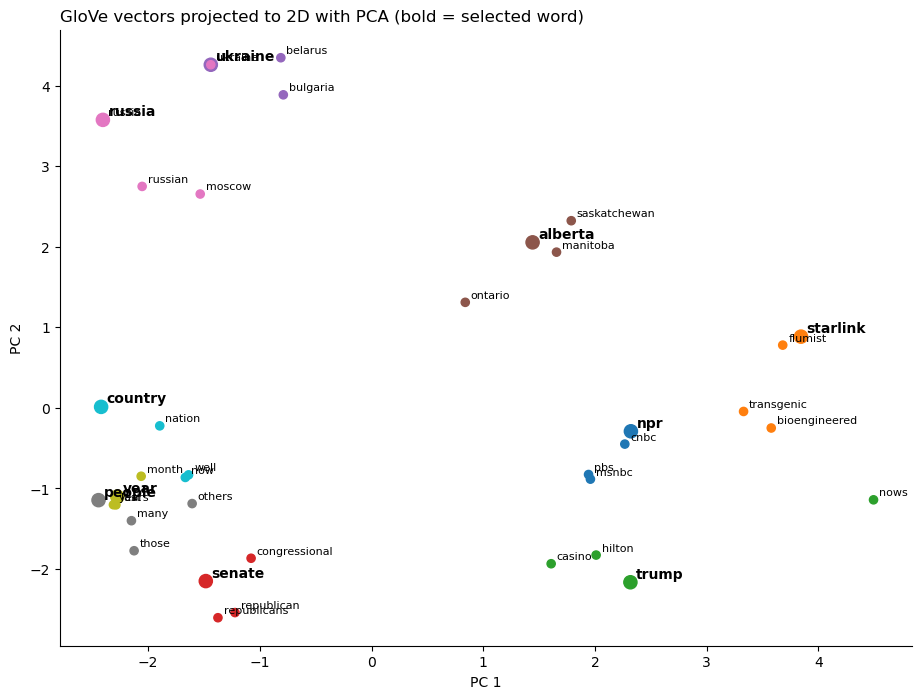

In [31]:
from sklearn.decomposition import PCA

plot_words = []
for w in WORDS:
    plot_words += [w] + [n for n, _ in wv.most_similar(w, topn=3)]
plot_words = list(dict.fromkeys(plot_words))

coords = PCA(n_components=2, random_state=0).fit_transform(np.vstack([wv[w] for w in plot_words]))

fig, ax = plt.subplots(figsize=(11, 8))
cmap = plt.get_cmap("tab10")
for gi, w in enumerate(WORDS):
    group = [w] + [n for n, _ in wv.most_similar(w, topn=3)]
    pts = np.array([coords[plot_words.index(g)] for g in group])
    ax.scatter(pts[:, 0], pts[:, 1], color=cmap(gi % 10), s=[90] + [35] * 3)
    for (x, y), g in zip(pts, group):
        ax.annotate(g, (x, y), xytext=(4, 3), textcoords="offset points",
                    fontsize=10 if g == w else 8, fontweight="bold" if g == w else "normal")
ax.set_title("GloVe vectors projected to 2D with PCA (bold = selected word)", loc="left")
ax.set_xlabel("PC 1")
ax.set_ylabel("PC 2")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

#### 10. Explanation of the visualization

**Technique.** PCA finds the directions in the 100-dimensional vector space along which the plotted words vary most, and projects each word onto the top two. It is a linear projection, so overall distances and directions are roughly preserved, but most of the information in the other 98 dimensions is lost. t-SNE is the non-linear alternative: it keeps local neighbourhoods tighter, but distances between clusters are not meaningful. PCA is easier to interpret and gives the same result every time it runs.

**interpretation**

- The model learned same category classes well because the words appear in similar contexts. Ex: Canadian provinces saskatchewan, manitoba, ontario are close to  alberta.  US broadcasters pbs, msnbc, cnbc are close to npr
- Senate is close to congressional, republican, republicans. These words are topically related to US politics, but don't mean the same thing. Embeddings capture words which "appear in the same contexts", not "meaning the same".
- Ukraine and Russia are each other's nearest neighbours, with belarus, bulgaria and moscow next. Countries at war are close because they are always written about together.
- The training data for GloVe is from 2014. Trump is close to hilton and casino which reflects Trump the businessman and not the politician in today's news. Starlink was launched in 2019, and has meaningless neighbours eg. flumist, probably because the word was rare and appeared in unrelated product-name contexts.
- Very frequent words appear in almost every context, so their neighbours include function words like "now", "well" rather than clear synonyms.

Embeddings work best for well-established named entities and category members. They are weaker for new terms and very general words, and they always reflect the time and source of their training data.

## 1.5 - Streamlit Search App (20)

Provide code and screenshots for the following search application for news articles that were scraped earlier:

1. Develop a streamlit application that would allow users to perform keyword search for articles.
2. Provide selectors for Tf-Idf, BM25 and Word2Vec and compare the quality of search results.
3. Point out examples where one algorithm works better than others.

#### 1-2. Streamlit app with TF-IDF / BM25 / Word2Vec selectors
The cell below writes `news_search_app.py`. Run it from a terminal with `streamlit run news_search_app.py` and take screenshots.

In [32]:
%%writefile news_search_app.py
import math
import re
from collections import Counter

import numpy as np
import pandas as pd
import streamlit as st
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

STOPWORDS = set(TfidfVectorizer(stop_words="english").get_stop_words()) | {"said", "says", "mr", "mrs"}


def tokenize(text):
    return re.findall(r"[a-z0-9]+(?:['-][a-z]+)*", text.lower())


def stem(w):
    if len(w) <= 3:
        return w
    if w.endswith("ies") and len(w) > 4:
        w = w[:-3] + "y"
    elif w.endswith("s") and not w.endswith(("ss", "us", "is")):
        w = w[:-1]
    for suf in ("ing", "ed"):
        if w.endswith(suf) and len(w) - len(suf) >= 3:
            w = w[: -len(suf)]
            if len(w) > 2 and w[-1] == w[-2] and w[-1] not in "lsz":
                w = w[:-1]
            break
    return w


def preprocess(text):
    return [stem(t) for t in tokenize(text) if t not in STOPWORDS]


class BM25:
    def __init__(self, corpus, k1=1.5, b=0.75):
        self.k1, self.b, self.N = k1, b, len(corpus)
        self.tf = [Counter(d) for d in corpus]
        self.dl = [len(d) for d in corpus]
        self.avgdl = sum(self.dl) / self.N
        dfc = Counter(t for d in corpus for t in set(d))
        self.idf = {t: math.log((self.N - n + 0.5) / (n + 0.5) + 1) for t, n in dfc.items()}

    def scores(self, q):
        out = np.zeros(self.N)
        for i, tf in enumerate(self.tf):
            norm = self.k1 * (1 - self.b + self.b * self.dl[i] / self.avgdl)
            out[i] = sum(self.idf[t] * tf[t] * (self.k1 + 1) / (tf[t] + norm) for t in q if t in tf)
        return out


@st.cache_data
def load_articles():
    return pd.read_csv("news_clean.csv").fillna("")


@st.cache_resource
def build_indexes(texts):
    tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), sublinear_tf=True)
    X = tfidf.fit_transform(texts)
    bm25 = BM25([preprocess(t) for t in texts])
    return tfidf, X, bm25


@st.cache_resource
def load_glove():
    import gensim.downloader as api
    return api.load("glove-wiki-gigaword-100")


def embed(wv, text):
    vecs = [wv[t] for t in tokenize(text) if t in wv.key_to_index and t not in STOPWORDS]
    return np.mean(vecs, axis=0) if vecs else np.zeros(wv.vector_size)


def search(method, query, df, tfidf, X, bm25):
    if method == "TF-IDF":
        return cosine_similarity(tfidf.transform([query]), X).ravel()
    if method == "BM25":
        return bm25.scores(preprocess(query))
    wv = load_glove()
    D = np.vstack([embed(wv, t) for t in df["text_clean"]])
    q = embed(wv, query)
    if not q.any():
        return np.zeros(len(df))
    return cosine_similarity(q[None, :], D).ravel()


def show_results(method, scores, df, k):
    st.subheader(method)
    order = np.argsort(scores)[::-1][:k]
    if scores[order[0]] <= 0:
        st.info("No matching articles.")
        return
    for rank, i in enumerate(order, 1):
        row = df.iloc[i]
        st.markdown(f"**{rank}. [{row['title']}]({row['url']})**  \n"
                    f"{row['source']} · {row['date']} · score `{scores[i]:.3f}`")
        st.caption(row["text_clean"][:250] + "...")


st.set_page_config(page_title="News Search", layout="wide")
st.title("News Article Search")

df = load_articles()
tfidf, X, bm25 = build_indexes(tuple(df["text_clean"]))

query = st.text_input("Search query", "climate change")
c1, c2 = st.columns([3, 1])
methods = c1.multiselect("Ranking method(s)", ["TF-IDF", "BM25", "Word2Vec"], default=["TF-IDF", "BM25", "Word2Vec"])
k = c2.slider("Results", 1, 10, 5)

if query and methods:
    cols = st.columns(len(methods))
    for col, m in zip(cols, methods):
        with col:
            show_results(m, search(m, query, df, tfidf, X, bm25), df, k)

Writing news_search_app.py


In [59]:
# app on: (opens http://localhost:8501)
!streamlit run news_search_app.py

2026-10-19 20:31:21.756 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://10.150.58.170:8501

  Help agents write better Streamlit apps?
  Install the official Streamlit skills by running streamlit skills in your terminal.

^C
  Stopping...


#### 3. Where one method beats another
The cell below runs the same queries through all three methods so you can pick examples for the write-up (exact keyword match vs synonyms / related concepts vs long or repeated-term documents).

In [34]:
def rank_all(query, k=3):
    tf_scores = cosine_similarity(tfidf.transform([query]), X_tfidf).ravel()
    bm_scores = np.array(bm25.rank(preprocess(query))[1])
    q = doc_vector(query)
    w2v_scores = cosine_similarity(q[None, :], doc_vecs).ravel() if q.any() else np.zeros(len(docs))
    out = {}
    for name, s in [("TF-IDF", tf_scores), ("BM25", bm_scores), ("Word2Vec", w2v_scores)]:
        top = np.argsort(s)[::-1][:k]
        out[name] = [f"{titles[i][:70]} ({s[i]:.2f})" if s[i] > 0 else "-" for i in top]
    return pd.DataFrame(out, index=[f"#{r}" for r in range(1, k + 1)])


for q in ["climate change", "election results", "military conflict", "economy and inflation", "football"]:
    print(f"\nQuery: {q!r}")
    display(rank_all(q))


Query: 'climate change'


,TF-IDF,BM25,Word2Vec
#1,A Kelvin wave raised sea levels on the West Coast. More are coming (0.08),Australian prime minister says lawmaker critically injured by car is ' (5.07),The AI doom scenario you've never heard of may be the hardest to stop (0.74)
#2,Australian prime minister says lawmaker critically injured by car is ' (0.06),A Kelvin wave raised sea levels on the West Coast. More are coming (3.84),A Kelvin wave raised sea levels on the West Coast. More are coming (0.73)
#3,Finland seeking one million land mines as it eyes Russian threat (0.06),Finland seeking one million land mines as it eyes Russian threat (3.33),Five ways El Niño is affecting the weather around the world (0.72)



Query: 'election results'


,TF-IDF,BM25,Word2Vec
#1,The real reason it's going to take a while to know who won in some mid (0.15),The real reason it's going to take a while to know who won in some mid (5.75),The real reason it's going to take a while to know who won in some mid (0.79)
#2,Hegseth meets Netanyahu in unannounced Israel visit (0.08),Alberta voters weigh future in Canada (4.77),Hegseth meets Netanyahu in unannounced Israel visit (0.77)
#3,"DOJ charges 28 with unlawful voting, other election-related offenses i (0.07)",Feds investigating suspicious letters sent to election officials and c (4.32),Alberta voters weigh future in Canada (0.76)



Query: 'military conflict'


,TF-IDF,BM25,Word2Vec
#1,Drone attack near market kills 80 in Sudan (0.10),"Houthi missile strike on Yemen camp kills 50 security recruits, author (4.32)","Houthi missile strike on Yemen camp kills 50 security recruits, author (0.84)"
#2,"Houthi missile strike on Yemen camp kills 50 security recruits, author (0.10)",Drone attack near market kills 80 in Sudan (4.06),Drone attack near market kills 80 in Sudan (0.84)
#3,160 people reported killed in escalating drone attacks across Sudan (0.07),160 people reported killed in escalating drone attacks across Sudan (3.42),Rashida Tlaib demands arrest of Israeli soldier linked to Hind Rajab d (0.83)



Query: 'economy and inflation'


,TF-IDF,BM25,Word2Vec
#1,Egyptian parliament delays vote on military support for Saudi Arabia (0.10),Egyptian parliament delays vote on military support for Saudi Arabia (3.82),Five ways El Niño is affecting the weather around the world (0.62)
#2,The AI doom scenario you've never heard of may be the hardest to stop (0.07),France's leaders vow to restore order after weekend of violent riots a (3.44),The AI doom scenario you've never heard of may be the hardest to stop (0.60)
#3,Florida issues arrest warrant for Cuban leader Raul Castro (0.06),The AI doom scenario you've never heard of may be the hardest to stop (2.88),"2026 midterms could be the most expensive on record. And, Macron conde (0.59)"



Query: 'football'


,TF-IDF,BM25,Word2Vec
#1,U.S. service member dies after rappelling incident at UT San Antonio f (0.07),U.S. service member dies after rappelling incident at UT San Antonio f (3.41),Tennis star Svitolina says emotional toll of Ukraine war led to Monfil (0.60)
#2,US airman dies as daredevil descent goes wrong before Texas college fo (0.06),US airman dies as daredevil descent goes wrong before Texas college fo (3.32),"Boy among 2 killed after truck drives onto Wichita soccer field, 11 ot (0.58)"
#3,"Four people killed in ‘violent, fast-moving’ fire at Canadian military (0.04)","Four people killed in ‘violent, fast-moving’ fire at Canadian military (2.10)",U.S. service member dies after rappelling incident at UT San Antonio f (0.58)


#### BM25 works best for specific keyword searches. Example: "election results".

BM25's top three results are all related to elections. They cover midterm election results, Alberta voters deciding their future, and suspicious letters sent to election officials. However, TF-IDF and Word2Vec both rank an article about Hegseth meeting Netanyahu in Israel at number two, even though it is not about elections. BM25 works well because it focuses on how often search words appear and adjusts for article length.

#### Word2Vec works best when relevant articles use different words. Example: "climate change".

BM25 ranks an article about an Australian lawmaker being hit by a car first, even though it is not about climate change. This may happen because the article uses the word "change" in a different context. Word2Vec finds more relevant articles, such as one about how El Niño affects weather and another about Kelvin waves and sea levels. These articles are related to climate, even if they do not use the exact words in the search. However, Word2Vec also ranks an unrelated AI article first, showing that it can sometimes return results that are only loosely related to the topic.

#### Word2Vec can also find words with similar meanings. Example: "football".

TF-IDF and BM25 mainly find articles that contain the exact word "football". These include stories about a service member who died while rappelling before a college football game and a fire at a Canadian military base. Word2Vec also finds an article about a soccer field in Wichita and another about tennis. Soccer is closely related to football in meaning, even though the words are different. This shows that Word2Vec can understand related concepts, but it may also return less relevant results because tennis is another type of sport.

#### TF-IDF and BM25 give similar results when the keywords are clear. Example: "military conflict".

All three algorithms find articles about drone attacks in Sudan and a Houthi missile strike on Yemen. When the search words appear directly in relevant articles, all three methods tend to produce similar results.

#### All algorithms struggle when there are no relevant articles. Example: "economy and inflation".

The dataset does not contain any articles specifically about the economy or inflation. TF-IDF and BM25 return an article about the Egyptian parliament that briefly mentions the economy, while Word2Vec returns an article about El Niño. None of the algorithms clearly indicates that no relevant articles were found. The low similarity scores are the only clue that the results may not be useful.